# Week 2 Task 2 — Gestalt principles of grouping

This notebook follows the Week 2 assignment brief and keeps each task in a separate file.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

path = Path('week2/assignments/data/stimuli_gestalt.csv')
if not path.exists():
    path = Path('assignments/data/stimuli_gestalt.csv')
if not path.exists():
    path = Path('d:/7_Semester/data-visualization/week2/assignments/data/stimuli_gestalt.csv')

df = pd.read_csv(path)
print(df.head())


       panel group       x       y colour   shape  size connector
0  proximity    g0  1.5130  1.6220   grey  circle    60      none
1  proximity    g0  1.2277  0.8682   grey  circle    60      none
2  proximity    g0  0.8520  0.0809   grey  circle    60      none
3  proximity    g0  0.6835  0.9270   grey  circle    60      none
4  proximity    g0  0.4485  1.3725   grey  circle    60      none


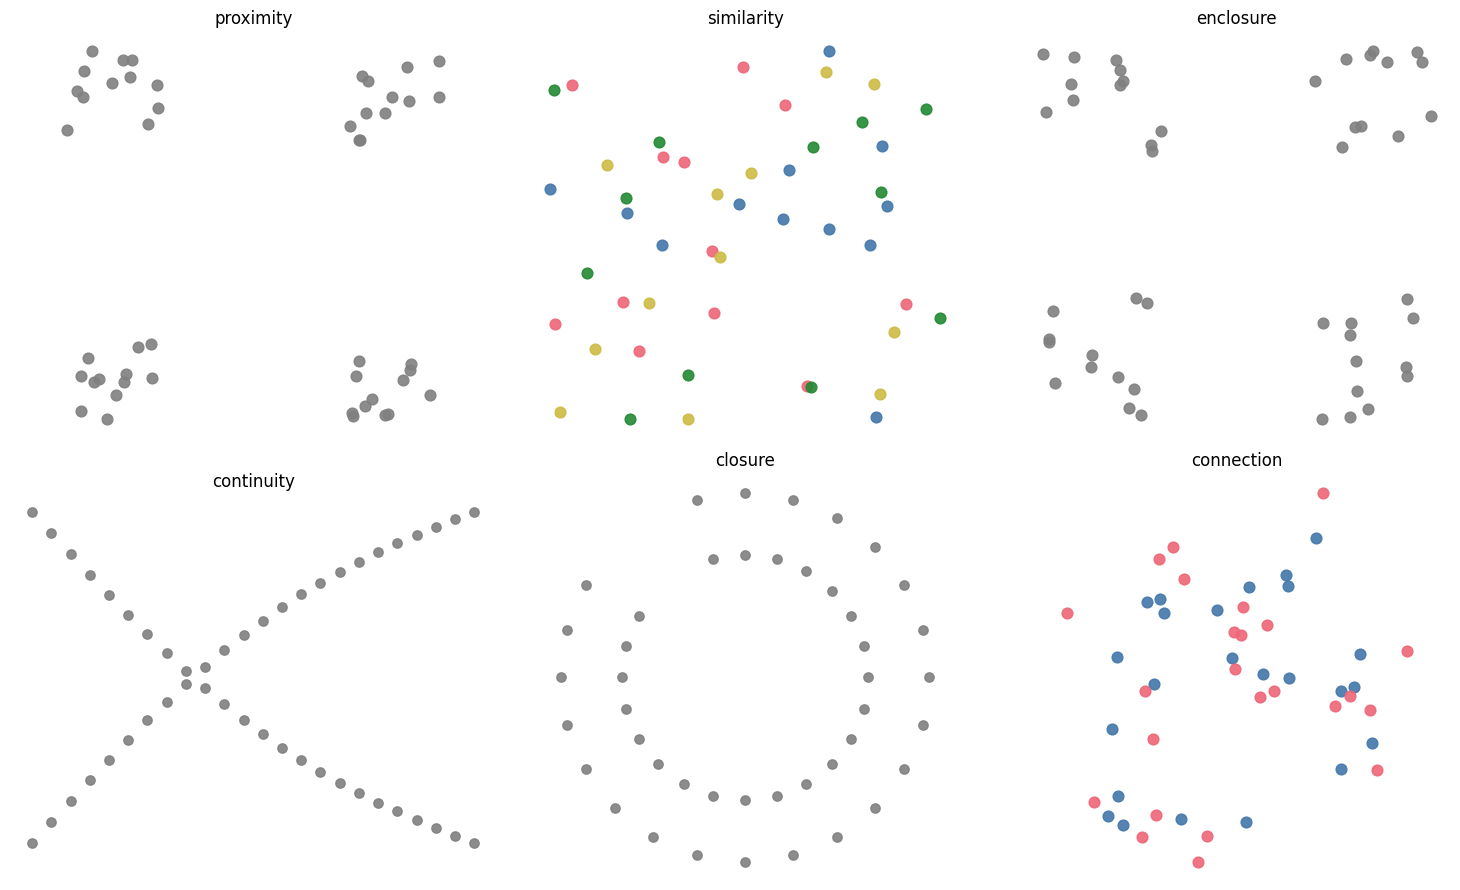

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, panel in zip(axes.flat, df['panel'].drop_duplicates()):
    g = df[df['panel'] == panel]
    for _, row in g.iterrows():
        ax.scatter(row['x'], row['y'], s=row['size'], c=row['colour'], alpha=0.9)
    ax.set_title(panel)
    ax.set_aspect('equal')
    ax.axis('off')
plt.tight_layout()
plt.show()


In [3]:
# Real reader data should be recorded in a small table: panel, true_groups, perceived_groups, match
panel_results = pd.DataFrame({
    'panel': [],
    'principle': [],
    'true_groups': [],
    'perceived_groups': [],
    'match': []
})
panel_results.head()


,panel,principle,true_groups,perceived_groups,match


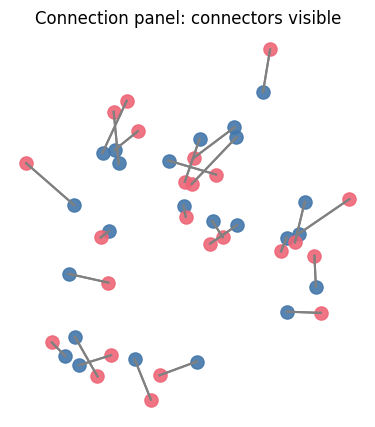

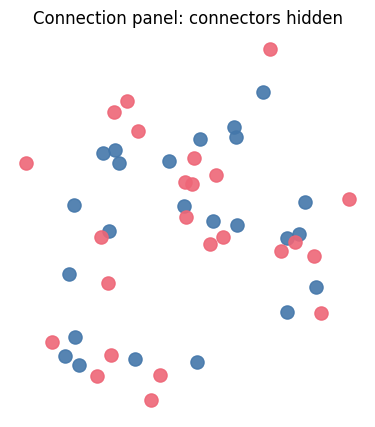

In [4]:
# Connection panel with and without connectors; use the same data but switch on the line drawing.
for show_connector in [True, False]:
    fig, ax = plt.subplots(figsize=(6, 5))
    g = df[df['panel'] == 'connection'].copy()
    for _, row in g.iterrows():
        ax.scatter(row['x'], row['y'], s=90, c=row['colour'], alpha=0.9)
        if show_connector:
            pair = row['connector']
            ends = g[g['connector'] == pair]
            if len(ends) == 2:
                ax.plot([ends.iloc[0]['x'], ends.iloc[1]['x']], [ends.iloc[0]['y'], ends.iloc[1]['y']], color='gray', linewidth=1.5)
    ax.set_title('Connection panel: connectors visible' if show_connector else 'Connection panel: connectors hidden')
    ax.set_aspect('equal')
    ax.axis('off')
    plt.show()


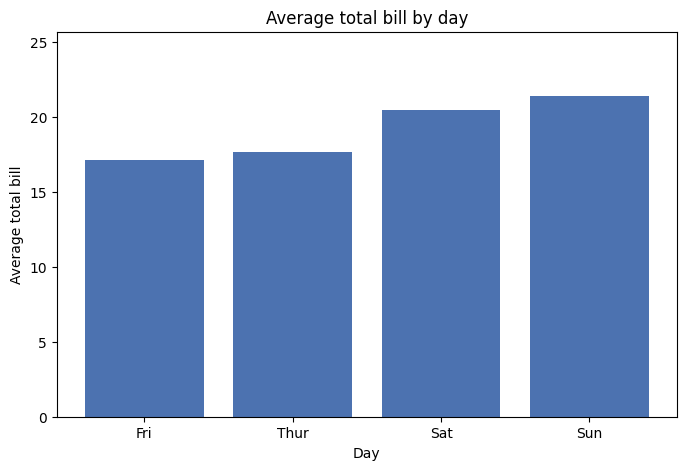

In [6]:
# This task uses proximity in a grouped bar chart. When the within-group gap is smaller than the between-group gap, the reader groups by cluster. Making the gaps equal removes that visual grouping, even though the data are unchanged.
# Load the tip data and compare the two versions.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

path = Path('week2/assignments/data/tips.csv')
if not path.exists():
    path = Path('assignments/data/tips.csv')
if not path.exists():
    path = Path('d:/7_Semester/data-visualization/week2/assignments/data/tips.csv')

tips = pd.read_csv(path)
by_day = tips.groupby('day')['total_bill'].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(by_day.index, by_day.values, color='#4c72b0')
ax.set_title('Average total bill by day')
ax.set_xlabel('Day')
ax.set_ylabel('Average total bill')
ax.set_ylim(0, max(by_day.values) * 1.2)
plt.show()

In [ ]:
# Direct labelling uses the Gestalt principle of connection or enclosure: the label is visually tied to the relevant mark, so the reader does not need to hold a colour in memory and compare it across a legend.
